# 05 · Objetivo (v): convergências e divergências com a literatura

> *"Discutir convergências e divergências entre os padrões identificados e a literatura sobre reorganização de atividades técnicas e competências profissionais, considerando suas possíveis implicações para a formação dos profissionais iniciantes."* (Seção 1.3, objetivo v)

Este notebook **não calcula nada novo sobre a base**: ele reúne os resultados dos notebooks `01` a `04` e `06` e os coloca lado a lado com o que os estudos
do artigo (Seção 2) afirmam. Para cada achado da literatura, a tabela diz **o que a amostra mostra**, **como ler** (convergência, parcial, tensão, não testável) e **o cuidado necessário**.

**Regra de ouro (da própria Seção 1 e 3.6 do artigo):** o corte transversal permite *descrever* e *aproximar*, não confirmar mudança nem causalidade.
Por isso, muitas linhas aparecem como *"não testável com esta base"*, o que é uma conclusão legítima e deve ser dita no texto.

> Execute os notebooks `01`–`04` e `06` antes deste: ele lê as tabelas CSV que eles geram. Os veredictos foram redigidos para a versão **v2026.10.27** dos dados; releia-os se mudar a versão.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
df["n_dim"] = df[["d_tecnica", "d_cog", "d_soc", "d_met"]].sum(axis=1)
R = lambda n: pd.read_csv(L.BASE / n)
cmp_, rg, comp, jul, apo, cf, rob = (R("tabela_04_com_sem_ia.csv"), R("tabela_04_regressao.csv"), R("tabela_03_complementaridade.csv"),
                                     R("tabela_03_julgamento.csv"), R("tabela_03_apoio_aprendizagem.csv"), R("tabela_02_conceito_ferramenta.csv"), R("tabela_06_robustez.csv"))
ia = R("ia_trechos_para_classificacao_manual.csv")
P = lambda s, c: 100 * s[c].mean()
dev, sup = df[df.grupo == L.G_DEV], df[df.grupo == L.G_SUP]
devj, deve, supj = dev[dev.nivel == "Júnior"], dev[dev.nivel == "Estágio"], sup[sup.nivel == "Júnior"]
dev_sem_ia = dev[dev.area != "Inteligência Artificial"]
tm = df[(df.nivel == "Júnior") & df.exp_meses_min.notna()]
CHAVES = list(L.COMPETENCIAS); ROT = {k: v[1] for k, v in L.COMPETENCIAS.items()}
print(f"Versão dos dados: {L.VERSAO} | {len(df):,} anúncios | Dev e dados: {len(dev):,} | Suporte e infra: {len(sup):,}")

Versão dos dados: tag | 9,964 anúncios | Dev e dados: 3,830 | Suporte e infra: 5,277


## 1. Painel-resumo: um gráfico por objetivo

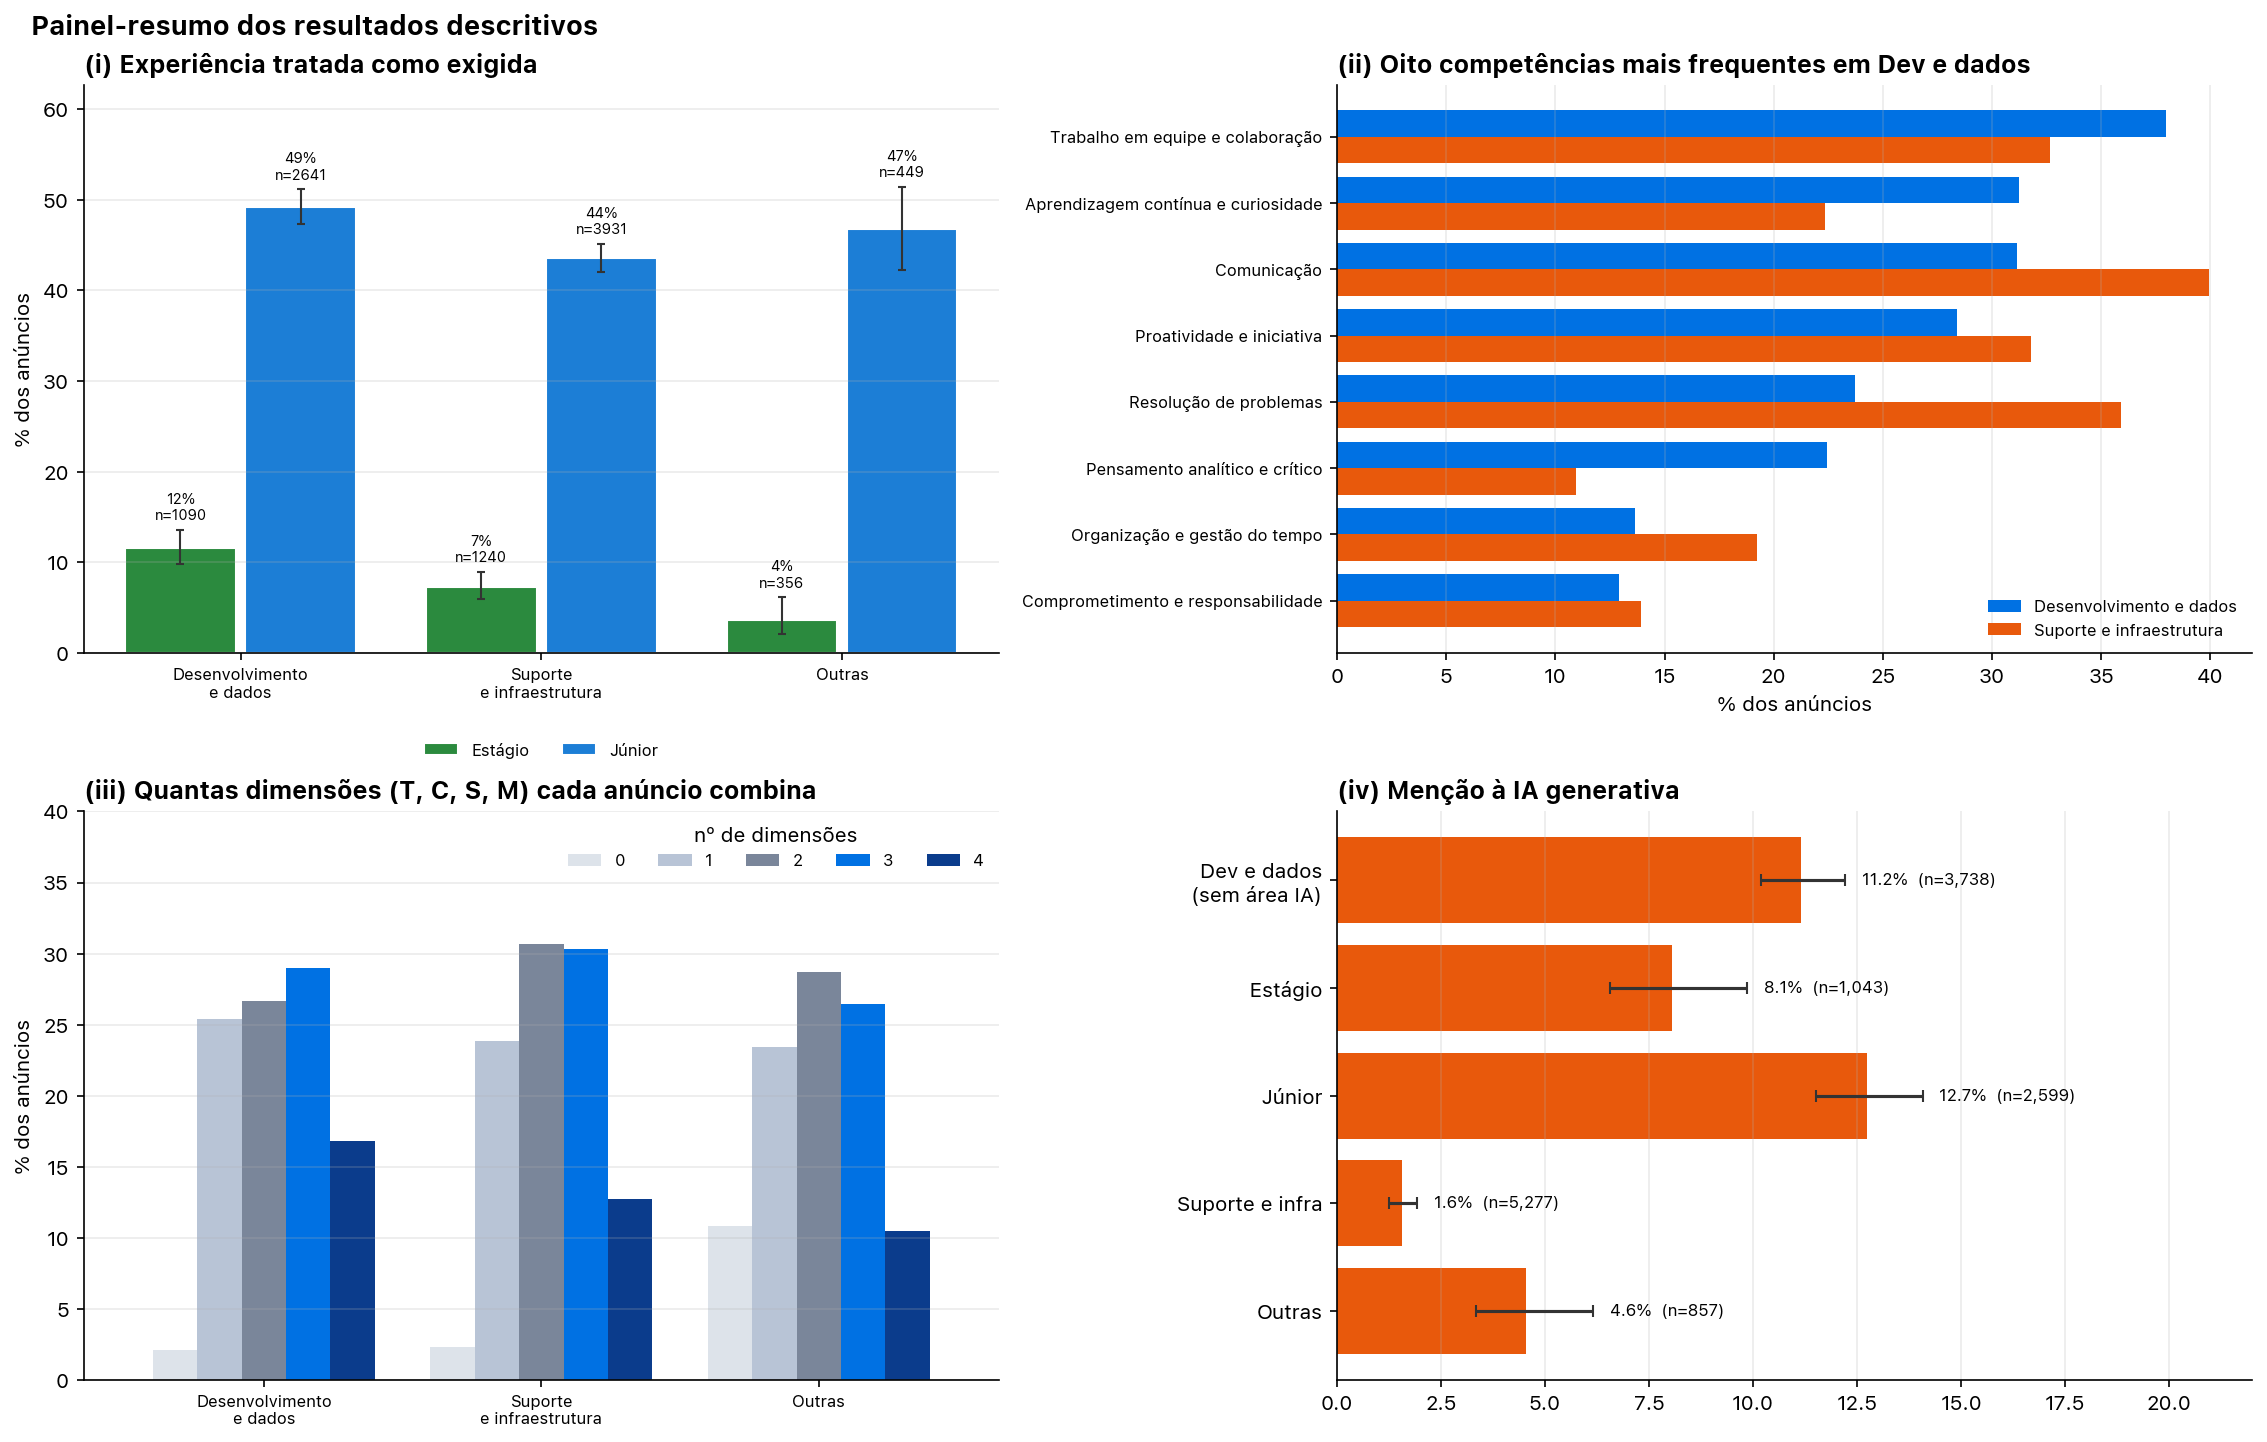

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
# (i) experiência exigida
ax = axes[0, 0]
t = L.tabela_prop(df[df.nivel.isin(L.NIVEIS_PRINCIPAIS)], "exp_obrigatoria", ["grupo", "nivel"])
L.barras_prop(ax, t, "grupo", "nivel", L.ORDEM_GRUPOS, L.NIVEIS_PRINCIPAIS, L.PALETA_NIVEL); ax.set_title("(i) Experiência tratada como exigida")
ax.set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
# (ii) competências em Dev x Suporte
ax = axes[0, 1]
ordem = sorted(CHAVES, key=lambda k: -P(dev, f"c_{k}"))[:8][::-1]
y = np.arange(len(ordem))
ax.barh(y + .2, [P(dev, f"c_{k}") for k in ordem], .4, color=L.PALETA[L.G_DEV], label=L.G_DEV)
ax.barh(y - .2, [P(sup, f"c_{k}") for k in ordem], .4, color=L.PALETA[L.G_SUP], label=L.G_SUP)
ax.set_yticks(y); ax.set_yticklabels([ROT[k] for k in ordem], fontsize=8); ax.set_xlabel("% dos anúncios"); ax.legend(fontsize=8)
ax.set_title("(ii) Oito competências mais frequentes em Dev e dados"); ax.grid(axis="y", visible=False)
# (iii) nº de dimensões
ax = axes[1, 0]
nd = pd.crosstab(df["grupo"], df["n_dim"], normalize="index").reindex(L.ORDEM_GRUPOS) * 100
nd.plot(kind="bar", ax=ax, color=["#DDE3EA", "#B8C4D6", "#7A869A", "#0071E3", "#0B3C8C"][:nd.shape[1]], width=.8)
ax.set_title("(iii) Quantas dimensões (T, C, S, M) cada anúncio combina"); ax.set_xlabel(""); ax.set_ylabel("% dos anúncios"); ax.set_ylim(0, 40)
ax.set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], rotation=0, fontsize=8); ax.legend(title="nº de dimensões", fontsize=8, ncol=5); ax.grid(axis="x", visible=False)
# (iv) IA generativa
ax = axes[1, 1]
rows = [("Dev e dados\n(sem área IA)", dev_sem_ia), ("   Estágio", dev_sem_ia[dev_sem_ia.nivel == "Estágio"]), ("   Júnior", dev_sem_ia[dev_sem_ia.nivel == "Júnior"]),
        ("Suporte e infra", sup), ("Outras", df[df.grupo == L.G_OUT])]
vals = [(n, *L.prop_ic(int(s.genai.sum()), len(s)), len(s)) for n, s in rows]
ax.barh([v[0] for v in vals][::-1], [v[1] for v in vals][::-1], color=["#7A869A", "#7A869A", "#1C7ED6", "#2B8A3E", "#0071E3"][::-1] if False else "#E8590C",
        xerr=[[v[1] - v[2] for v in vals][::-1], [v[3] - v[1] for v in vals][::-1]], error_kw=dict(ecolor="#333", capsize=3))
for i, v in enumerate(vals[::-1]): ax.text(v[3] + .4, i, f"{v[1]:.1f}%  (n={v[4]:,})", va="center", fontsize=8)
ax.set_xlim(0, 22); ax.set_title("(iv) Menção à IA generativa"); ax.grid(axis="y", visible=False)
fig.suptitle("Painel-resumo dos resultados descritivos", x=.01, ha="left", fontweight="bold", fontsize=13)
L.salvar(fig, "05_painel_resumo"); plt.show()

## 2. Matriz de convergência e divergência

Legenda da coluna **Leitura**:
- **Convergência descritiva**: o retrato da amostra é compatível com o que o estudo descreve (sem afirmar mudança).
- **Convergência parcial**: compatível em parte, ou dependente de escolhas de controle ou de classificação.
- **Tensão aparente**: os números não reproduzem a ênfase do estudo (as medidas costumam ser diferentes).
- **Não testável com esta base**: o desenho transversal, a ausência de vagas sênior ou a natureza do indicador impedem a comparação.

In [3]:
def row(tema, lit, fonte, amostra, leitura, cuidado):
    return {"Tema": tema, "O que a literatura relata": lit, "Fonte": fonte, "O que a amostra mostra": amostra, "Leitura": leitura, "Cuidado": cuidado}

cs = cmp_.set_index("variavel"); rr = rg.set_index("variavel")
apr = cs.loc["Aprendizagem contínua e curiosidade"]; pens = cs.loc["Pensamento analítico e crítico"]
comp_dev = comp[comp.grupo == L.G_DEV].set_index("quartil")["razão"]; comp_sup = comp[comp.grupo == L.G_SUP].set_index("quartil")["razão"]
ordem_dev = sorted(CHAVES, key=lambda k: -P(dev, f"c_{k}"))
rank_pens = ordem_dev.index("pensamento_analitico") + 1
conc_dev = df[df.grupo == L.G_DEV]; n_conc = conc_dev.sk_tec.apply(lambda l: sum(s in L.CONCEITOS for s in l)).mean(); n_ferr = conc_dev.sk_tec.apply(lambda l: sum(s in L.FERRAMENTAS for s in l)).mean()
j = jul.set_index(["grupo", "nivel"])["pct"]; ap = apo.set_index(["grupo", "nivel"])["pct"]
val_pct = 100 * ia["assoc_validacao_automatica"].mean()
q1_ia = int(((dev_sem_ia.quartil_tam == "Q1 (curto)") & dev_sem_ia.genai).sum())

linhas = [
 row("Retração relativa de vagas júnior",
     "Vagas de nível júnior em software caíram 14–15% em relação às sêniores após o ChatGPT (EUA, ~5,7 milhões de anúncios, 2019–2025).",
     "Westby, Modestino e Cheng (2026)",
     f"A base só tem vagas de entrada (n = {len(df):,}) e {100 * df['data_pub'].between('2026-08-01', '2026-10-31').mean():.0f}% foram publicadas entre ago e out/2026 (efeito da expansão da coleta). Não há vagas sênior nem série histórica.",
     "Não testável com esta base",
     "Não use a amostra para confirmar nem refutar. Dizer isso explicitamente na Seção 5 reforça a honestidade metodológica."),
 row("Queda de ocupação de desenvolvedores jovens",
     "Emprego de desenvolvedores de 22 a 25 anos nos EUA caiu cerca de 20% desde 2024.",
     "Stanford AI Index 2026",
     "Indicador de ocupação por faixa etária; a base mede anúncios de vagas de entrada, sem idade dos ocupantes.",
     "Não testável com esta base",
     "Medidas distintas (já ressalvado na Seção 2.2 do artigo). Não comparar numericamente."),
 row("Experiência exigida elevada nas vagas de entrada",
     "A experiência média exigida em vagas de software aumentou, sobretudo dentro dos mesmos títulos de cargo.",
     "Westby et al. (2026)",
     f"Em Dev e dados, {P(devj, 'exp_obrigatoria'):.0f}% dos anúncios de Júnior tratam experiência como exigida (Estágio: {P(deve, 'exp_obrigatoria'):.0f}%). Entre os {len(tm)} Júnior com tempo declarado, a mediana do mínimo é de {tm.exp_meses_min.median():.0f} meses.",
     "Convergência parcial",
     "Retrato compatível com a existência de barreira de experiência no nível Júnior; **não mostra aumento**. O tipo mais frequente é 'experiência em/com tecnologia', o mais fraco."),
 row("Paradoxo da experiência / barreira do primeiro emprego",
     "Vagas de entrada pedem experiência prévia, excluindo recém-formados; gestores relatam dificuldades com experiência e qualificação.",
     "Dobslaw et al. (2023); Lopes et al. (2024); Brasscom e PROA (2025)",
     f"Só {P(devj, 'exp_nao_exige'):.1f}% dos Júnior em Dev e dados e {P(supj, 'exp_nao_exige'):.1f}% dos Júnior em Suporte afirmam não exigir experiência; no Estágio de Dev e dados, {P(deve, 'exp_nao_exige'):.1f}%.",
     "Convergência descritiva",
     "Anúncios expressam expectativas, não decisões de contratação. Estudos de gestores (n pequeno) e de jovens têm outra natureza."),
 row("Habilidades complementares nas vagas júnior",
     "As vagas de entrada remanescentes deslocaram-se para comunicação interpessoal, resolução de problemas e atenção a detalhes.",
     "Westby et al. (2026); Deming (2017)",
     f"Em Dev e dados Júnior: comunicação {P(devj, 'c_comunicacao'):.0f}%, resolução de problemas {P(devj, 'c_resolucao_problemas'):.0f}%, atenção a detalhes {P(devj, 'c_atencao_detalhes'):.0f}%. No Suporte Júnior: {P(supj, 'c_comunicacao'):.0f}%, {P(supj, 'c_resolucao_problemas'):.0f}% e {P(supj, 'c_atencao_detalhes'):.0f}%.",
     "Convergência parcial",
     "Competências presentes em parcela relevante, mas minoritária; atenção a detalhes é baixa. Sem série temporal, não há como falar em crescimento. Resolução de problemas é mais frequente em Suporte que em Dev (efeito de área, não de IA)."),
 row("Complementaridade entre habilidade técnica e social",
     "Habilidades matemáticas e sociais atuam de forma complementar no mercado de trabalho.",
     "Deming (2017)",
     f"P(socioemocional | técnica) ÷ P(socioemocional | sem técnica): Dev e dados {comp_dev.get('Q1 (curto)', np.nan):.2f} (quartil curto; único com suporte) e {comp_dev.get('Todos', np.nan):.2f} (todos); Suporte {comp_sup.min():.2f}–{comp_sup.max():.2f} (quartis e total).",
     "Convergência parcial",
     f"Só sustentada em Dev e dados e Outras; em Suporte desaparece ao controlar o tamanho do texto. Como {100 * df.d_tecnica.mean():.0f}% dos anúncios têm alguma habilidade técnica, o grupo de comparação 'sem técnica' é pequeno. Interpretar com cautela."),
 row("IA explícita como requisito nas vagas júnior",
     "Requisitos explícitos de IA/ML diminuíram nas vagas júnior; hipótese de que a familiaridade com IA virou expectativa implícita (não confirmada).",
     "Westby et al. (2026); Rak (2026)",
     f"{P(dev_sem_ia, 'genai'):.1f}% dos anúncios de Dev e dados (sem a área IA) mencionam IA generativa; {P(sup, 'genai'):.1f}% em Suporte. Pré-classificação automática: {100 * (ia.pre_classificacao_automatica == 'Requisito profissional').mean():.0f}% como requisito, {100 * (ia.pre_classificacao_automatica == 'Atividade prevista').mean():.0f}% como atividade.",
     "Não testável com esta base",
     "Sem tempo, não se vê queda; sem entrevistas, não se vê expectativa implícita. A baixa explicitação é compatível com as duas leituras. Classificação R/A/C ainda depende da leitura manual."),
 row("Recrutadores valorizam proficiência com ferramentas de IA",
     "Parte dos 32 recrutadores prefere candidatos que demonstram habilidade com essas ferramentas, e a maioria (65,6%, segundo o fichamento) relata organizações sem diretrizes oficiais para considerá-las na seleção.",
     "Chen et al. (2024)",
     f"Menção explícita em {P(dev_sem_ia, 'genai'):.1f}% dos anúncios de Dev e dados; {ia.shape[0]} anúncios no recorte, dos quais {100 * (ia.pre_classificacao_automatica == 'Requisito profissional').mean():.0f}% como requisito (automático).",
     "Tensão aparente",
     "Medidas diferentes: percepção declarada de 32 recrutadores vs texto de anúncios. A baixa explicitação nos anúncios é coerente com 'sem diretrizes formais', o que é uma inferência, não um resultado."),
 row("Uso crítico da IA (pensamento crítico, avaliação de respostas)",
     "Recrutadores citam pensamento crítico, resolução de problemas e avaliação das respostas das ferramentas.",
     "Chen et al. (2024)",
     f"Entre anúncios com IA vs sem (padronizado por tamanho): pensamento analítico {pens.dif_pad:+.1f} p.p. (IC {pens.dif_lo:+.1f} a {pens.dif_hi:+.1f}); na regressão, OR = {rr.loc['Pensamento analítico', 'OR']:.2f}. Trechos com palavras de revisão/validação por perto: {val_pct:.0f}% (automático).",
     "Convergência parcial",
     "Sinal sugestivo, mas sensível ao controle (o IC da diferença padronizada inclui zero). A associação com 'revisão/validação' precisa da classificação manual."),
 row("Aprendizagem associada à assistência de IA",
     "Ganhos de produtividade maiores para trabalhadores menos experientes e evidências de aprendizagem com assistente de IA.",
     "Brynjolfsson, Li e Raymond (2025)",
     f"Anúncios com menção à IA têm mais aprendizagem contínua e curiosidade: {apr.dif_pad:+.1f} p.p. (IC {apr.dif_lo:+.1f} a {apr.dif_hi:+.1f}) após padronizar; OR = {rr.loc['Aprendizagem contínua', 'OR']:.2f} com controles.",
     "Convergência parcial",
     "Um anúncio que pede disposição para aprender não demonstra aprendizagem efetiva nem ganho de produtividade. Aproximação indireta, não teste."),
 row("Conceitos × tecnologias",
     "Documentos acadêmicos enfatizam conceitos; anúncios enfatizam tecnologias.",
     "Dobslaw et al. (2023)",
     f"Dev e dados: média de {n_ferr:.1f} ferramentas e {n_conc:.1f} conceitos por anúncio. Suporte: conceitos em {cf[(cf.grupo == L.G_SUP) & (cf.tipo == 'Conceitos')].pct.iloc[0]:.0f}% e ferramentas em {cf[(cf.grupo == L.G_SUP) & (cf.tipo == 'Ferramentas')].pct.iloc[0]:.0f}% dos anúncios.",
     "Convergência parcial",
     "A amostra só traz o lado dos anúncios; a comparação com currículos exige outra fonte. A divisão conceito × ferramenta é proposta desta análise e muda o resultado em Suporte (onde Windows e Hardware não estão em nenhuma lista)."),
 row("Pensamento analítico como competência central",
     "Pensamento analítico lidera as competências mais importantes; curiosidade e aprendizagem contínua têm importância crescente.",
     "WEF, Future of Jobs 2025",
     f"Em Dev e dados, pensamento analítico é a {rank_pens}ª entre 13 competências do dicionário ({P(dev, 'c_pensamento_analitico'):.0f}%); aprendizagem contínua aparece em {P(deve, 'c_aprendizagem_continua'):.0f}% dos Estágios e {P(devj, 'c_aprendizagem_continua'):.0f}% dos Júnior.",
     "Convergência parcial",
     "O WEF mede a importância percebida por empregadores em todas as ocupações. Aqui, menções por palavra-chave em vagas de entrada. Comparação qualitativa, não numérica."),
 row("Tarefas estruturadas e acúmulo de experiência",
     "A automação de tarefas júnior pode comprometer a acumulação de experiência que forma o trabalhador; a IA substitui primeiro as tarefas estruturadas.",
     "Asriyan, Reichardt e Shelegia (2026); Cunha (2026)",
     f"Índice de julgamento (% de verbos de julgamento): Dev e dados Júnior {j[(L.G_DEV, 'Júnior')]:.0f}% vs Estágio {j[(L.G_DEV, 'Estágio')]:.0f}%; Suporte Júnior {j[(L.G_SUP, 'Júnior')]:.0f}%. Apoio à aprendizagem declarado: Estágio {ap[(L.G_DEV, 'Estágio')]:.0f}% vs Júnior {ap[(L.G_DEV, 'Júnior')]:.0f}% em Dev e dados.",
     "Não testável com esta base",
     "O mecanismo é dinâmico (efeitos futuros sobre carreira). A amostra só descreve a natureza das tarefas e as condições de aprendizagem declaradas. Suporte descreve mais execução do que julgamento, compatível com a ideia de tarefas mais estruturadas, mas não testa substituição. Listas de verbos são exploratórias."),
 row("Funções de suporte nível 1 e 2 em retração",
     "Projeção de queda de 38% em suporte L1/L2, -18% em frontend júnior e -12% em full stack júnior.",
     "Gupta (2025)",
     f"Suporte e infraestrutura é {100 * len(sup) / len(df):.0f}% da amostra; menção à IA generativa: {P(sup, 'genai'):.1f}%.",
     "Não testável com esta base",
     "Projeções de fontes secundárias; a amostra não tem série temporal. O peso do suporte na base pode refletir os termos de busca do projeto, não o mercado."),
 row("Percepção dos jovens sobre IA",
     "58% dos jovens consideram a IA estratégica para a carreira; parte teme substituição.",
     "Brasscom e PROA (2025)",
     "Pesquisa de percepção; a base de anúncios não mede percepções.",
     "Não testável com esta base",
     "Constructos diferentes. Usar apenas como contexto, como o artigo já faz na Seção 2.4."),
]
matriz = pd.DataFrame(linhas)
cor = {"Convergência descritiva": "#D3F9D8", "Convergência parcial": "#FFF3BF", "Tensão aparente": "#FFD8A8", "Não testável com esta base": "#E9ECEF"}
def pinta(v): return f"background-color:{cor.get(v, 'white')};font-weight:bold"
sty = (matriz.style.hide(axis="index").map(pinta, subset=["Leitura"])
       .set_properties(**{"white-space": "normal", "text-align": "left", "vertical-align": "top", "font-size": "12px"})
       .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("font-size", "12px")]}]))
display(sty)
matriz.to_csv(L.BASE / "tabela_05_matriz_literatura.csv", index=False, encoding="utf-8-sig")

Tema,O que a literatura relata,Fonte,O que a amostra mostra,Leitura,Cuidado
Retração relativa de vagas júnior,"Vagas de nível júnior em software caíram 14–15% em relação às sêniores após o ChatGPT (EUA, ~5,7 milhões de anúncios, 2019–2025).","Westby, Modestino e Cheng (2026)","A base só tem vagas de entrada (n = 9,964) e 84% foram publicadas entre ago e out/2026 (efeito da expansão da coleta). Não há vagas sênior nem série histórica.",Não testável com esta base,Não use a amostra para confirmar nem refutar. Dizer isso explicitamente na Seção 5 reforça a honestidade metodológica.
Queda de ocupação de desenvolvedores jovens,Emprego de desenvolvedores de 22 a 25 anos nos EUA caiu cerca de 20% desde 2024.,Stanford AI Index 2026,"Indicador de ocupação por faixa etária; a base mede anúncios de vagas de entrada, sem idade dos ocupantes.",Não testável com esta base,Medidas distintas (já ressalvado na Seção 2.2 do artigo). Não comparar numericamente.
Experiência exigida elevada nas vagas de entrada,"A experiência média exigida em vagas de software aumentou, sobretudo dentro dos mesmos títulos de cargo.",Westby et al. (2026),"Em Dev e dados, 49% dos anúncios de Júnior tratam experiência como exigida (Estágio: 12%). Entre os 547 Júnior com tempo declarado, a mediana do mínimo é de 12 meses.",Convergência parcial,"Retrato compatível com a existência de barreira de experiência no nível Júnior; **não mostra aumento**. O tipo mais frequente é 'experiência em/com tecnologia', o mais fraco."
Paradoxo da experiência / barreira do primeiro emprego,"Vagas de entrada pedem experiência prévia, excluindo recém-formados; gestores relatam dificuldades com experiência e qualificação.",Dobslaw et al. (2023); Lopes et al. (2024); Brasscom e PROA (2025),"Só 2.1% dos Júnior em Dev e dados e 1.3% dos Júnior em Suporte afirmam não exigir experiência; no Estágio de Dev e dados, 5.7%.",Convergência descritiva,"Anúncios expressam expectativas, não decisões de contratação. Estudos de gestores (n pequeno) e de jovens têm outra natureza."
Habilidades complementares nas vagas júnior,"As vagas de entrada remanescentes deslocaram-se para comunicação interpessoal, resolução de problemas e atenção a detalhes.",Westby et al. (2026); Deming (2017),"Em Dev e dados Júnior: comunicação 28%, resolução de problemas 26%, atenção a detalhes 10%. No Suporte Júnior: 40%, 39% e 8%.",Convergência parcial,"Competências presentes em parcela relevante, mas minoritária; atenção a detalhes é baixa. Sem série temporal, não há como falar em crescimento. Resolução de problemas é mais frequente em Suporte que em Dev (efeito de área, não de IA)."
Complementaridade entre habilidade técnica e social,Habilidades matemáticas e sociais atuam de forma complementar no mercado de trabalho.,Deming (2017),P(socioemocional | técnica) ÷ P(socioemocional | sem técnica): Dev e dados 2.15 (quartil curto; único com suporte) e 2.34 (todos); Suporte 0.79–1.21 (quartis e total).,Convergência parcial,"Só sustentada em Dev e dados e Outras; em Suporte desaparece ao controlar o tamanho do texto. Como 94% dos anúncios têm alguma habilidade técnica, o grupo de comparação 'sem técnica' é pequeno. Interpretar com cautela."
IA explícita como requisito nas vagas júnior,Requisitos explícitos de IA/ML diminuíram nas vagas júnior; hipótese de que a familiaridade com IA virou expectativa implícita (não confirmada).,Westby et al. (2026); Rak (2026),"11.2% dos anúncios de Dev e dados (sem a área IA) mencionam IA generativa; 1.6% em Suporte. Pré-classificação automática: 37% como requisito, 26% como atividade.",Não testável com esta base,"Sem tempo, não se vê queda; sem entrevistas, não se vê expectativa implícita. A baixa explicitação é compatível com as duas leituras. Classificação R/A/C ainda depende da leitura manual."
Recrutadores valorizam proficiência com ferramentas de IA,"Parte dos 32 recrutadores prefere candidatos que demonstram habilidade com essas ferramentas, e a maioria (65,6%, segundo o fichamento) relata organ

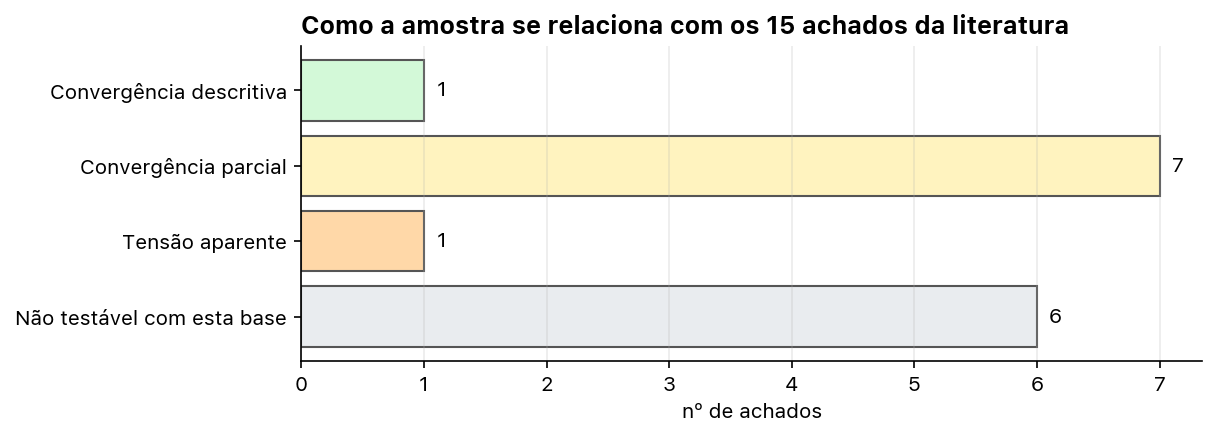

In [4]:
cont = matriz["Leitura"].value_counts().reindex(list(cor)).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(cont.index[::-1], cont.values[::-1], color=[cor[k] for k in cont.index[::-1]], edgecolor="#555")
for i, v in enumerate(cont.values[::-1]): ax.text(v + .1, i, str(v), va="center")
ax.set_title(f"Como a amostra se relaciona com os {len(matriz)} achados da literatura"); ax.grid(axis="y", visible=False); ax.set_xlabel("nº de achados")
L.salvar(fig, "05_resumo_leitura"); plt.show()

## 3. Resumo para a Seção 4 e 5 (números gerados da base)

In [5]:
Markdown(f"""
**Base.** {len(df):,} anúncios (versão `{L.VERSAO}`), dos quais {len(dev):,} em Desenvolvimento e dados, {len(sup):,} em Suporte e infraestrutura e {len(df[df.grupo == L.G_OUT]):,} em Outras.

**(i) Experiência e formação.** Em Dev e dados, {P(devj, 'exp_obrigatoria'):.0f}% dos Júnior e {P(deve, 'exp_obrigatoria'):.0f}% dos Estágios tratam experiência como exigida; o tempo mínimo mediano em Júnior é de {tm.exp_meses_min.median():.0f} meses. Menos de {max(P(devj, 'exp_nao_exige'), P(supj, 'exp_nao_exige')):.0f}% dos Júnior dizem não exigi-la.

**(ii) Competências.** Em Dev e dados, as mais frequentes são {', '.join(f"{ROT[k].lower()} ({P(dev, 'c_' + k):.0f}%)" for k in ordem_dev[:3])}. Aprendizagem contínua é mais frequente no Estágio ({P(deve, 'c_aprendizagem_continua'):.0f}%) que no Júnior ({P(devj, 'c_aprendizagem_continua'):.0f}%).

**(iii) Combinações.** {100 * (df['n_dim'] >= 3).mean():.0f}% dos anúncios combinam ao menos três dimensões (Dev e dados: {100 * (dev['n_dim'] >= 3).mean():.0f}%; Suporte: {100 * (sup['n_dim'] >= 3).mean():.0f}%). O índice de julgamento em Júnior é de {j[(L.G_DEV, 'Júnior')]:.0f}% em Dev e dados e {j[(L.G_SUP, 'Júnior')]:.0f}% em Suporte.

**(iv) IA generativa.** {P(dev_sem_ia, 'genai'):.1f}% dos anúncios de Dev e dados (sem a área IA) a mencionam. Com padronização por tamanho do texto, esses anúncios têm {apr.dif_pad:+.0f} p.p. de aprendizagem contínua e {cs.loc['Autonomia', 'dif_pad']:+.0f} p.p. de autonomia, sem diferença em comunicação ou resolução de problemas.

**(v) Literatura.** Dos {len(matriz)} achados comparados, convergência descritiva: {cont['Convergência descritiva']}; convergência parcial: {cont['Convergência parcial']}; tensão aparente: {cont['Tensão aparente']}; não testáveis com a base: {cont['Não testável com esta base']}.
""")


**Base.** 9,964 anúncios (versão `tag`), dos quais 3,830 em Desenvolvimento e dados, 5,277 em Suporte e infraestrutura e 857 em Outras.

**(i) Experiência e formação.** Em Dev e dados, 49% dos Júnior e 12% dos Estágios tratam experiência como exigida; o tempo mínimo mediano em Júnior é de 12 meses. Menos de 2% dos Júnior dizem não exigi-la.

**(ii) Competências.** Em Dev e dados, as mais frequentes são trabalho em equipe e colaboração (38%), aprendizagem contínua e curiosidade (31%), comunicação (31%). Aprendizagem contínua é mais frequente no Estágio (41%) que no Júnior (27%).

**(iii) Combinações.** 44% dos anúncios combinam ao menos três dimensões (Dev e dados: 46%; Suporte: 43%). O índice de julgamento em Júnior é de 40% em Dev e dados e 15% em Suporte.

**(iv) IA generativa.** 11.2% dos anúncios de Dev e dados (sem a área IA) a mencionam. Com padronização por tamanho do texto, esses anúncios têm +15 p.p. de aprendizagem contínua e +7 p.p. de autonomia, sem diferença em comunicação ou resolução de problemas.

**(v) Literatura.** Dos 15 achados comparados, convergência descritiva: 1; convergência parcial: 7; tensão aparente: 1; não testáveis com a base: 6.


## 4. Pendências do artigo que estes notebooks resolvem ou alimentam

| Marcador | Pendência | Situação |
|---|---|---|
| `[P1]` | Resultados no resumo e no abstract | Números do bloco acima (versão a fixar). |
| `[P5]` | 2 a 3 exemplos de anúncios que combinem comunicação, resolução de problemas e IA | Candidatos no notebook `03` (seção 7); escolha final das autoras. |
| `[P11]` | Precisão do dicionário por competência | **Planilha pronta** (`validacao_dicionario_amostra.csv`); falta a leitura das duas pesquisadoras. |
| `[P12]` | Onde disponibilizar scripts e dicionário | Esta pasta tem tudo; decidir apêndice ou repositório. Antes, **fixar a versão dos dados** (ver notebook `00`). |
| Seção 3.4 (objetivo iv) | Classificação manual R/A/C e validação | **Planilha pronta** (`ia_trechos_para_classificacao_manual.csv`); falta a leitura e o kappa. |
| Seção 3.2 | Números do snapshot de 29/10 | **Não reproduzíveis** com as versões publicadas (notebook `00`). |

## 5. Perguntas para a orientadora
1. Qual versão dos dados será a oficial no artigo (a tag `v2026.10.27`, a base atual ou o snapshot interno de 29/10)?
2. O tipo de experiência "em/com tecnologia" conta como exigência de experiência prévia na Seção 3.4-d, ou só tempo mínimo e experiência prévia explícita?
3. Idiomas (Inglês, Espanhol) entram como competência técnica? Aqui ficam de fora.
4. A dimensão metacognitiva será ampliada (autorregulação, abertura a feedback) para acompanhar a definição da Seção 2.1, ou a definição será estreitada?
5. A classificação conceito × ferramenta (usada no diálogo com Dobslaw et al.) é aceitável, ou prefere-se outra?
6. Os índices de julgamento e de apoio à aprendizagem (extensões exploratórias dos notebooks `03`) entram no artigo ou ficam como trabalho futuro?
7. Como apresentar o resultado de *resolução de problemas*, que muda de sinal conforme o controle usado na comparação com × sem IA (notebook `04`)?

## 6. Escolhas desta análise que precisam de validação
- Recorte de benefícios por **aproximação** das regras do projeto, sobre texto achatado (notebook `00`).
- Dicionário de competências com **qualificadores** para reduzir falsos positivos; precisão ainda não medida.
- Experiência: tipos, **tempo máximo plausível de 10 anos**, exclusão de menções sobre a empresa, heurística *obrigatória × desejável*.
- Competência técnica **sem idiomas**; classificação conceito × ferramenta.
- Pré-classificação R/A/C e listas de verbos de execução e julgamento são **regras simples**, não substituem a leitura humana.
- O quartil de texto mais curto tem poucos anúncios com IA (ver notebook `04`); a padronização é frágil nesse ponto.
- K-means é exploratório e de baixa silhueta, adequado a gerar hipóteses.